# Exploratory Data Analysis: CMAPSS FD001

**CS5998 Capstone: Predicting Remaining Useful Life in Turbofan Engines**

FD001 is the project's primary subset: one operating condition and one fault mode (High-Pressure Compressor degradation). This notebook answers the questions the modelling pipeline depends on:

1. Is the data complete and how long do engines run?
2. Which sensors carry no information and can be dropped?
3. How does each remaining sensor change as an engine approaches failure?
4. Which sensors are related to RUL, and which duplicate each other?
5. Is the RUL cap of 125 cycles supported by the data?
6. Can the sensors be combined into a single health index?

Sensor analysis uses **training engines only**, so nothing from the test set influences modelling decisions. The test set appears only in Section 1, to compare its size and lengths with training.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src.config import load_config, resolve_path
from src.data.download import main as download_cmapss
from src.data.load import OP_SETTINGS, SENSORS, load_subset
from src.data.quality import find_cycle_gaps, missing_report
from src.features.labels import add_train_rul

config = load_config()
RUL_CAP = config["preprocessing"]["rul_cap"]
DROP_SENSORS = [f"sensor_{i}" for i in config["preprocessing"]["drop_sensors"]["FD001"]]

if not (resolve_path(config["data"]["raw_dir"]) / "train_FD001.txt").exists():
    download_cmapss([])

BLUE, ORANGE, RED, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#e34948", "#0b0b0b", "#52514e", "#e6e5e0"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#104281", "#2a78d6", "#f0efec", "#e34948", "#a32323"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.bottom": False, "ytick.left": False,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.precision", 3)

train, test, rul = load_subset("FD001")
labelled = add_train_rul(train, cap=None).rename(columns={"rul": "rul_linear"})
labelled["rul_capped"] = labelled["rul_linear"].clip(upper=RUL_CAP)

## 1. Data overview

### Size and completeness

In [2]:
def summarise(df):
    lengths = df.groupby("unit")["cycle"].max()
    return {
        "engines": df["unit"].nunique(), "rows": len(df),
        "shortest engine (cycles)": lengths.min(), "median engine (cycles)": lengths.median(),
        "longest engine (cycles)": lengths.max(),
        "channels with missing values": len(missing_report(df)), "skipped cycles": len(find_cycle_gaps(df)),
    }

pd.DataFrame({"train": summarise(train), "test": summarise(test)})

,train,test
engines,100.0,100.0
rows,20631.0,13096.0
shortest engine (cycles),128.0,31.0
median engine (cycles),199.0,133.5
longest engine (cycles),362.0,303.0
channels with missing values,0.0,0.0
skipped cycles,0.0,0.0


### Engine lengths and test-set RUL

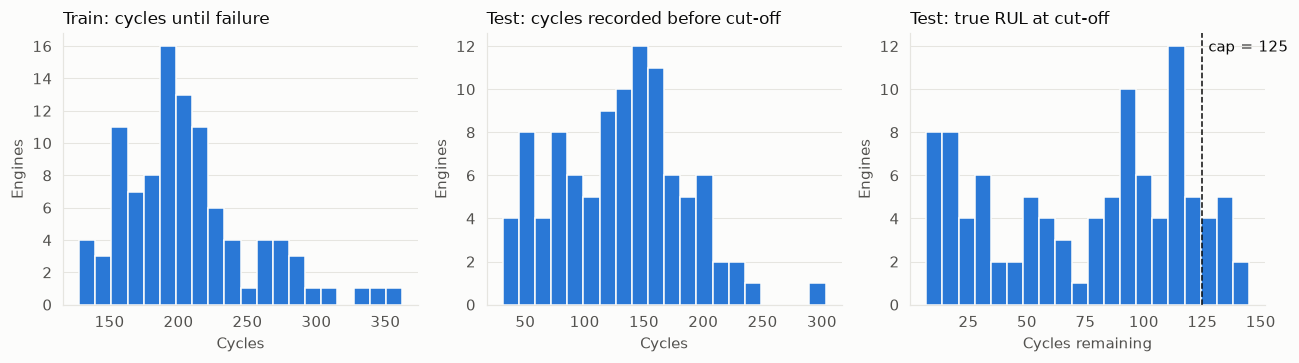

Shortest test engine: 31 cycles (window size 30)
Test engines with true RUL above the cap: 11 of 100


In [3]:
train_life = train.groupby("unit")["cycle"].max()
test_seen = test.groupby("unit")["cycle"].max()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
panels = [
    (train_life, "Train: cycles until failure", "Cycles"),
    (test_seen, "Test: cycles recorded before cut-off", "Cycles"),
    (rul["rul"], "Test: true RUL at cut-off", "Cycles remaining"),
]
for ax, (values, title, xlabel) in zip(axes, panels):
    ax.hist(values, bins=20, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
    ax.set(title=title, xlabel=xlabel, ylabel="Engines")
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[2].axvline(RUL_CAP, color=INK, linewidth=1, linestyle="--")
axes[2].annotate(f"cap = {RUL_CAP}", (RUL_CAP, axes[2].get_ylim()[1]), xytext=(4, -12),
                 textcoords="offset points", ha="left", color=INK)
fig.tight_layout()
plt.show()

print(f"Shortest test engine: {test_seen.min()} cycles (window size {config['preprocessing']['window_size']})")
print(f"Test engines with true RUL above the cap: {(rul['rul'] > RUL_CAP).sum()} of {len(rul)}")

**Findings**

- **The data is complete:** no missing values and no skipped cycles in either split, so imputation changes nothing on FD001.
- **Engine lifetimes vary widely:** training engines fail after 128 to 362 cycles (median 199), so cycle number alone says little about remaining life.
- **Every test engine has a full window:** the shortest has 31 cycles, just above the 30-cycle window. The first 29 cycles of each training engine have only a partial window, which the feature pipeline must handle.
- **11 of 100 test engines have a true RUL above the cap** (up to 145). A model trained on a target capped at 125 will not predict above 125, so these engines carry a built-in underestimate of up to 20 cycles. Evaluation must state whether test RUL is capped.

## 2. Which channels carry no information?

For each channel: how much it varies, how many distinct values it takes, how often its most common value appears, and its correlation with RUL.

In [4]:
channels = [*OP_SETTINGS, *SENSORS]
variation = pd.DataFrame({
    "std": train[channels].std(),
    "distinct values": train[channels].nunique(),
    "most common value (% of rows)": [100 * train[c].value_counts(normalize=True).iloc[0] for c in channels],
    "correlation with RUL": [
        labelled[c].corr(labelled["rul_capped"]) if labelled[c].nunique() > 1 else np.nan for c in channels
    ],
})
variation[variation["distinct values"].le(2) | variation.index.isin(OP_SETTINGS)]

,std,distinct values,most common value (% of rows),correlation with RUL
op_setting_1,2.187e-03,158,2.002,-0.006
op_setting_2,2.931e-04,13,10.198,-0.007
op_setting_3,0.000e+00,1,100.000,NaN
sensor_1,0.000e+00,1,100.000,NaN
sensor_5,5.329e-15,1,100.000,NaN
sensor_6,1.389e-03,2,98.032,-0.108
sensor_10,0.000e+00,1,100.000,NaN
sensor_16,3.470e-18,1,100.000,NaN
sensor_18,0.000e+00,1,100.000,NaN
sensor_19,0.000e+00,1,100.000,NaN


In [5]:
sensor_6_by_stage = labelled.assign(
    stage=pd.cut(labelled["rul_linear"], [-1, 50, 125, 400], labels=["RUL 0-50", "RUL 51-125", "RUL above 125"])
).groupby("stage", observed=True)["sensor_6"].value_counts(normalize=True).unstack().mul(100)
sensor_6_by_stage.columns = [f"{c} (% of rows)" for c in sensor_6_by_stage.columns]
sensor_6_by_stage

,21.6 (% of rows),21.61 (% of rows)
stage,,
RUL 0-50,0.039,99.961
RUL 51-125,1.107,98.893
RUL above 125,3.997,96.003


**Findings**

- **Six sensors are exactly constant:** 1, 5, 10, 16, 18 and 19, along with `op_setting_3`. They carry no information and are dropped. (The tiny `std` shown for sensors 5 and 16 is floating-point rounding; each has one distinct value.)
- **Sensor 6 is near-constant, not zero variance.** It takes two values one measurement step apart, with 98.0% of rows at 21.61. The rarer value 21.60 becomes less common towards failure (4.0% of rows above RUL 125, 0.04% in the last 50 cycles), but the correlation with RUL is only -0.11. Dropping it remains reasonable, but the reason should be stated as near-zero variance. **The PDD lists it as zero variance and should be reworded.**
- **`op_setting_1` and `op_setting_2` show no relationship with RUL** (correlations of -0.006 and -0.007). They are small variations around FD001's single operating condition, so they should be left out of the FD001 inputs. This does not carry over to FD002, where operating settings define six distinct conditions.

## 3. How sensors change as engines approach failure

Engines have different lifetimes, so they are aligned on **cycles before failure**. The line is the median across engines; the band covers the middle 80% of engines. Failure is at the right edge of each panel.

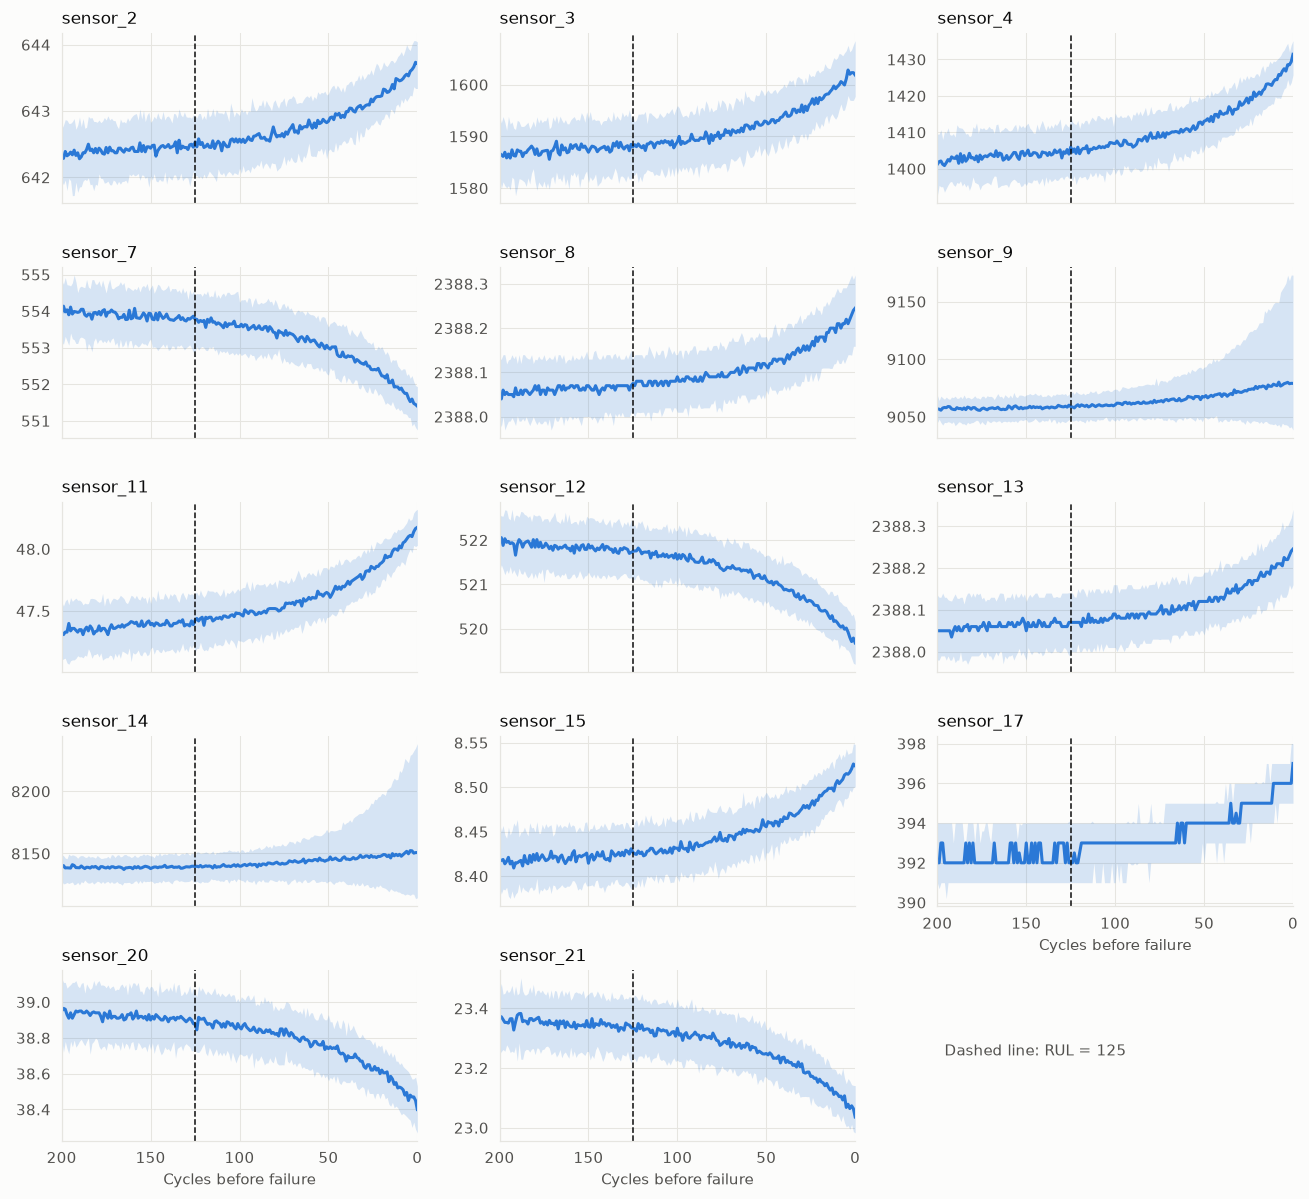

In [6]:
KEPT_SENSORS = [s for s in SENSORS if s not in DROP_SENSORS]
window = labelled[labelled["rul_linear"] <= 200]
by_rul = window.groupby("rul_linear")[KEPT_SENSORS]
median, low, high = by_rul.median(), by_rul.quantile(0.1), by_rul.quantile(0.9)

fig, axes = plt.subplots(5, 3, figsize=(12, 11), sharex=True)
for ax, sensor in zip(axes.flat, KEPT_SENSORS):
    ax.fill_between(median.index, low[sensor], high[sensor], color=BLUE, alpha=0.18, linewidth=0)
    ax.plot(median.index, median[sensor], color=BLUE)
    ax.axvline(RUL_CAP, color=INK, linewidth=1, linestyle="--")
    ax.set_title(sensor)
    ax.ticklabel_format(axis="y", useOffset=False)
axes.flat[-1].axis("off")
axes.flat[-1].text(0.02, 0.5, f"Dashed line: RUL = {RUL_CAP}", color=MUTED, transform=axes.flat[-1].transAxes)
for ax in axes.flat[:-1]:
    ax.set_xlim(200, 0)
for ax in (axes[3, 2], *axes[4, :2]):
    ax.set_xlabel("Cycles before failure")
    ax.tick_params(labelbottom=True)
fig.tight_layout()
plt.show()

### Noise in a single engine

The charts above average over engines, which hides how noisy one engine is. This is why the pipeline computes statistics over a 30-cycle window.

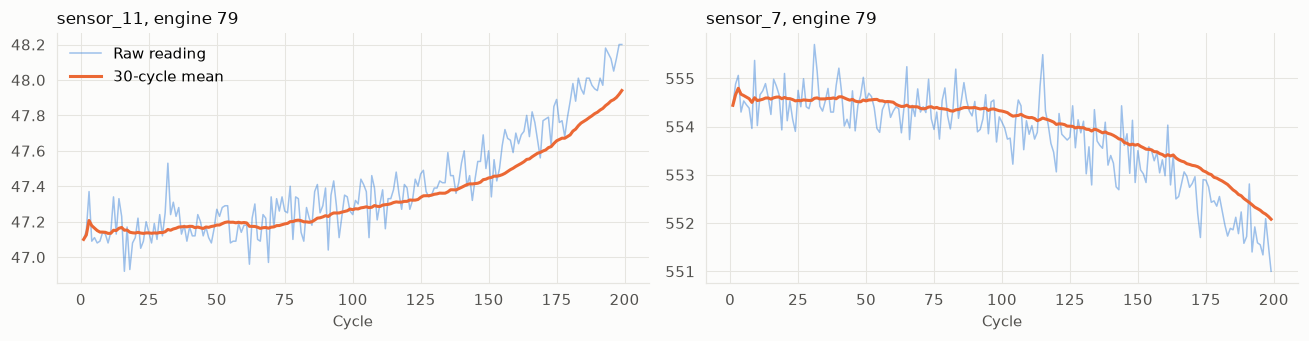

Engine 79: cycle-to-cycle change vs overall spread, median across sensors = 0.69


In [7]:
unit = train_life.sort_values().index[len(train_life) // 2]
engine = train[train["unit"] == unit].set_index("cycle")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, sensor in zip(axes, ["sensor_11", "sensor_7"]):
    ax.plot(engine.index, engine[sensor], color=BLUE, linewidth=1, alpha=0.45, label="Raw reading")
    ax.plot(engine.index, engine[sensor].rolling(30, min_periods=1).mean(), color=ORANGE, label="30-cycle mean")
    ax.set(title=f"{sensor}, engine {unit}", xlabel="Cycle")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

raw_to_trend = engine[KEPT_SENSORS].diff().std() / engine[KEPT_SENSORS].std()
print(f"Engine {unit}: cycle-to-cycle change vs overall spread, median across sensors = {raw_to_trend.median():.2f}")

### Do sensors 9 and 14 behave differently between engines?

These two have the weakest link with RUL. Comparing engines shows whether that is because the sensor is uninformative or because each engine sits at a different level.

In [8]:
def between_engine_share(sensor):
    healthy = labelled[labelled["rul_linear"] > RUL_CAP]
    return healthy.groupby("unit")[sensor].mean().var() / healthy[sensor].var()

shares = pd.Series({s: between_engine_share(s) for s in KEPT_SENSORS}).sort_values(ascending=False)
shares.mul(100).round(1).rename("% of healthy-phase variance between engines").to_frame().head(6)

,% of healthy-phase variance between engines
sensor_14,88.3
sensor_9,77.6
sensor_8,70.1
sensor_13,69.0
sensor_11,66.1
sensor_12,61.6


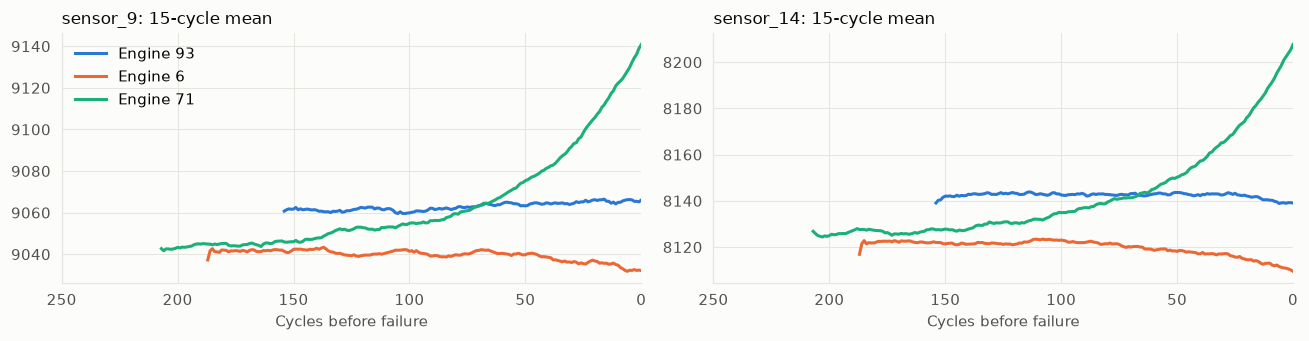

sensor_9: rises near failure in 71 of 100 engines; correlation of that change with engine lifetime = +0.13
sensor_14: rises near failure in 58 of 100 engines; correlation of that change with engine lifetime = +0.14
sensor_11: rises near failure in 100 of 100 engines; correlation of that change with engine lifetime = -0.11


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
sample_units = train_life.sort_values().index[[10, 35, 60, 85]]
colours = [BLUE, ORANGE, "#1baf7a"]
for ax, sensor in zip(axes, ["sensor_9", "sensor_14"]):
    for unit_id, colour in zip(sample_units[:3], colours):
        one = labelled[labelled["unit"] == unit_id].set_index("rul_linear")[sensor].rolling(15, min_periods=1).mean()
        ax.plot(one.index, one, color=colour, label=f"Engine {unit_id}")
    ax.set(title=f"{sensor}: 15-cycle mean", xlabel="Cycles before failure", xlim=(250, 0))
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

def change_near_failure(sensor):
    late = labelled[labelled["rul_linear"] < 20].groupby("unit")[sensor].mean()
    earlier = labelled[labelled["rul_linear"].between(100, 124)].groupby("unit")[sensor].mean()
    return late - earlier

for sensor in ["sensor_9", "sensor_14", "sensor_11"]:
    change = change_near_failure(sensor)
    print(f"{sensor}: rises near failure in {(change > 0).sum()} of {len(change)} engines; "
          f"correlation of that change with engine lifetime = {change.corr(train_life):+.2f}")

**Findings**

- **12 of the 14 kept sensors share a clear pattern:** little movement while RUL is high, then a change that accelerates towards failure. Sensors 2, 3, 4, 8, 11, 13, 15 and 17 rise; 7, 12, 20 and 21 fall.
- **Single engines are noisy.** For the engine shown, the typical cycle-to-cycle change is 0.69 of the sensor's whole spread over its life, which supports using rolling statistics. The 30-cycle mean also lags: near failure it sits visibly behind the raw reading, so the latest reading is worth keeping as a feature alongside the rolling statistics.
- **Sensors 8, 13 and 17 are coarse.** Sensor 17 moves in whole-number steps, with 13 distinct values, so short-window statistics on it will be stepped.
- **Sensors 9 and 14 do not move consistently.** They rise near failure in only 71 and 58 of 100 engines, against 100 of 100 for sensor 11. Their median barely moves while the band fans out near failure, and the change is not explained by engine lifetime (correlations of +0.13 and +0.14).
- **Engines differ in their baseline level.** Between-engine differences account for over 60% of healthy-phase variance in the six sensors listed, and 88% for sensor 14, consistent with the unknown initial wear and manufacturing variation NASA describes. **Train and validation data must therefore be split by engine.** Splitting by row would let a model recognise an engine's baseline and overstate its accuracy.

## 4. Relationships between sensors and RUL

### Correlation with RUL

Correlation is computed against the capped target, because that is what the models will learn.

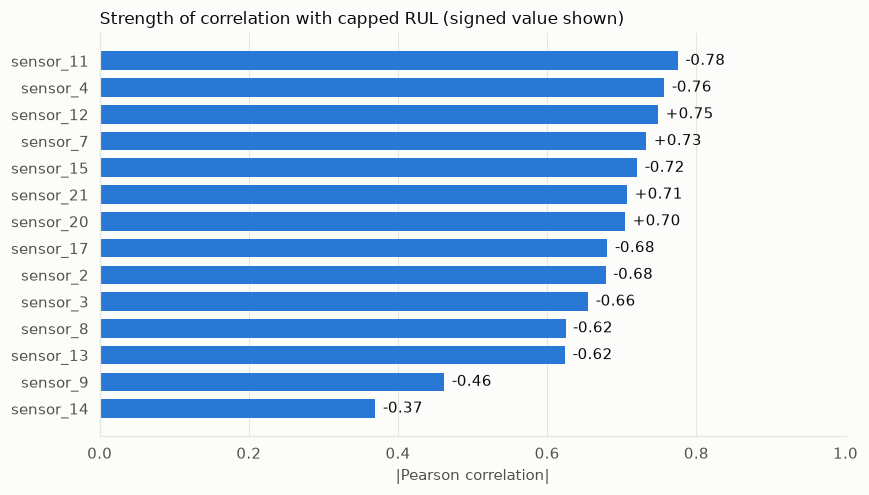

In [10]:
with_rul = labelled[KEPT_SENSORS].corrwith(labelled["rul_capped"]).sort_values(key=np.abs)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(with_rul.index, with_rul.abs(), color=BLUE, height=0.7)
for y, (value, signed) in enumerate(zip(with_rul.abs(), with_rul)):
    ax.text(value + 0.01, y, f"{signed:+.2f}", va="center", color=INK)
ax.set(title="Strength of correlation with capped RUL (signed value shown)", xlabel="|Pearson correlation|", xlim=(0, 1))
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### Correlation between sensors

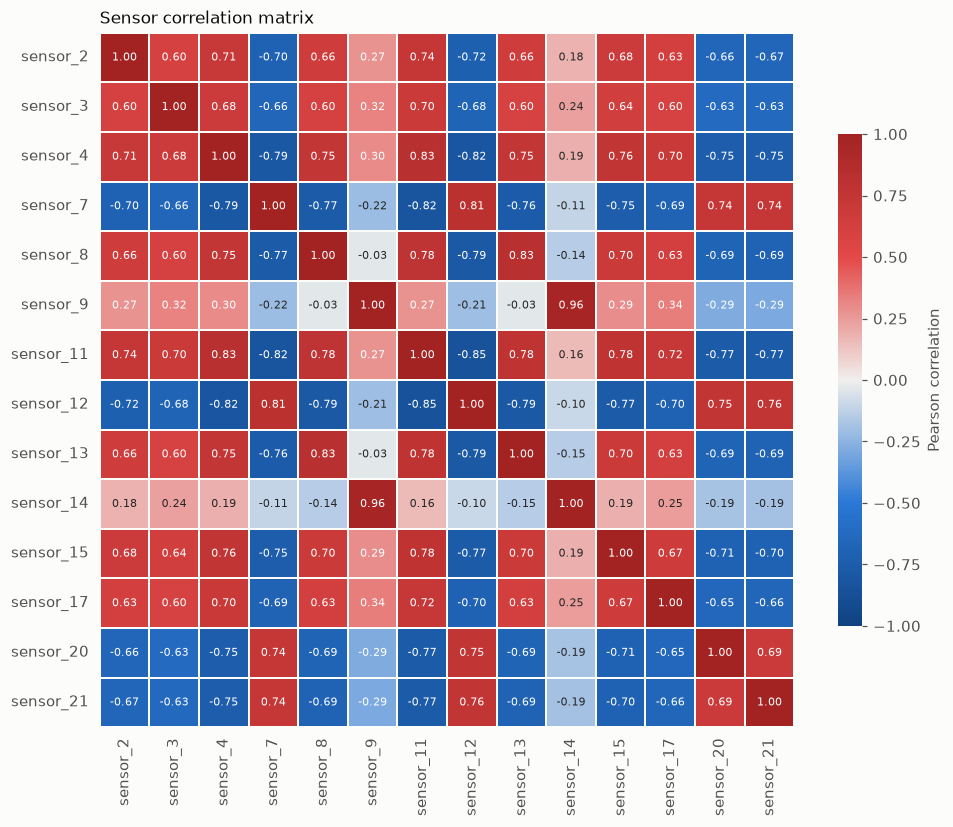

,,correlation
sensor A,sensor B,
sensor_9,sensor_14,0.963
sensor_11,sensor_12,-0.847
sensor_4,sensor_11,0.830
sensor_8,sensor_13,0.826
sensor_7,sensor_11,-0.823
sensor_4,sensor_12,-0.816
sensor_7,sensor_12,0.813


In [11]:
corr = labelled[KEPT_SENSORS].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7.5},
            linewidths=1, linecolor="#fcfcfb", square=True, cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Sensor correlation matrix")
ax.grid(False)
fig.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.8].sort_values(key=np.abs, ascending=False)
strong.rename("correlation").rename_axis(["sensor A", "sensor B"]).to_frame()

**Findings**

- **The strongest linear links with capped RUL** are sensor 11 (-0.78), sensor 4 (-0.76), sensor 12 (+0.75) and sensor 7 (+0.73). Twelve of the 14 sensors reach at least 0.62 in magnitude.
- **Sensors 9 (-0.46) and 14 (-0.37) are the weakest,** matching their inconsistent behaviour in Section 3.
- **Some sensors are redundant.** Seven pairs exceed 0.8 in magnitude. The strongest is 9 and 14 (0.96), then 8 and 13 (0.83), while 4, 7, 11 and 12 form a tightly linked group.
- **Pearson correlation has limits here.** It measures straight-line relationships across pooled rows, while the trends in Section 3 are curved, so non-linear models may gain more from these sensors than the values suggest.

**Decision:** keep all 14 sensors for the first models. Tree models and neural networks both tolerate correlated inputs, and these correlations alone do not show that a sensor is unhelpful. Removing sensor 14 or 13 can be tested later against validation error.

## 5. RUL target: is the cap supported?

The PDD assumes engines show little degradation until around RUL = 125, and gives a grid-search range of 110 to 140 for checking that. If the assumption holds, a typical sensor should stay flat while RUL is high, then start moving. The next chart standardises all 14 sensors, flips them so that all rise towards failure, and averages them.

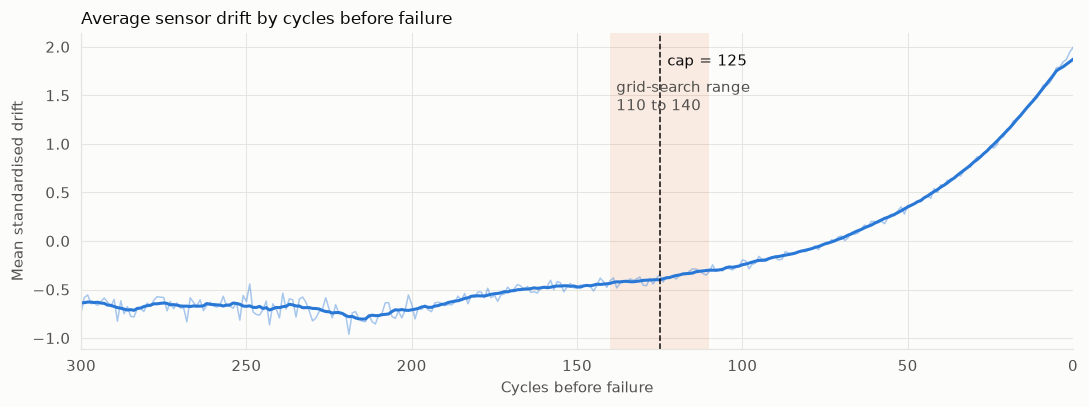

Healthy baseline (RUL >= 200): -0.689, noise: 0.088
Drift first exceeds baseline + 3 x noise at RUL = 139
Share of total drift already reached at the cap: 11.3%
Engines contributing to the baseline (lifetime above 200 cycles): 46 of 100


In [12]:
scaled = pd.DataFrame(StandardScaler().fit_transform(train[KEPT_SENSORS]), columns=KEPT_SENSORS, index=train.index)
signs = np.sign(labelled[KEPT_SENSORS].corrwith(labelled["rul_linear"])) * -1
drift = (scaled * signs).mean(axis=1).groupby(labelled["rul_linear"]).median()
drift = drift[drift.index <= 300].sort_index()

baseline = drift[drift.index >= 200].median()
spread = drift[drift.index >= 200].std()
smooth = drift.rolling(11, center=True, min_periods=1).mean()
crossed = smooth[smooth > baseline + 3 * spread]
departure = crossed.index.max()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(drift.index, drift, color=BLUE, linewidth=1, alpha=0.4)
ax.plot(smooth.index, smooth, color=BLUE)
ax.axvspan(110, 140, color=ORANGE, alpha=0.12, linewidth=0)
ax.axvline(RUL_CAP, color=INK, linewidth=1, linestyle="--")
ax.annotate(f"cap = {RUL_CAP}", (RUL_CAP, smooth.max()), xytext=(5, -4), textcoords="offset points", color=INK)
ax.annotate("grid-search range\n110 to 140", (140, smooth.max() * 0.72), xytext=(4, 0), textcoords="offset points", color=MUTED)
ax.set(title="Average sensor drift by cycles before failure", xlabel="Cycles before failure",
       ylabel="Mean standardised drift", xlim=(300, 0))
fig.tight_layout()
plt.show()

print(f"Healthy baseline (RUL >= 200): {baseline:.3f}, noise: {spread:.3f}")
print(f"Drift first exceeds baseline + 3 x noise at RUL = {departure}")
print(f"Share of total drift already reached at the cap: {(smooth.loc[RUL_CAP] - baseline) / (smooth.loc[0] - baseline):.1%}")
print(f"Engines contributing to the baseline (lifetime above 200 cycles): {(train_life > 200).sum()} of {len(train_life)}")

Rows with RUL above 125 (labelled 125 after capping): 38.9%


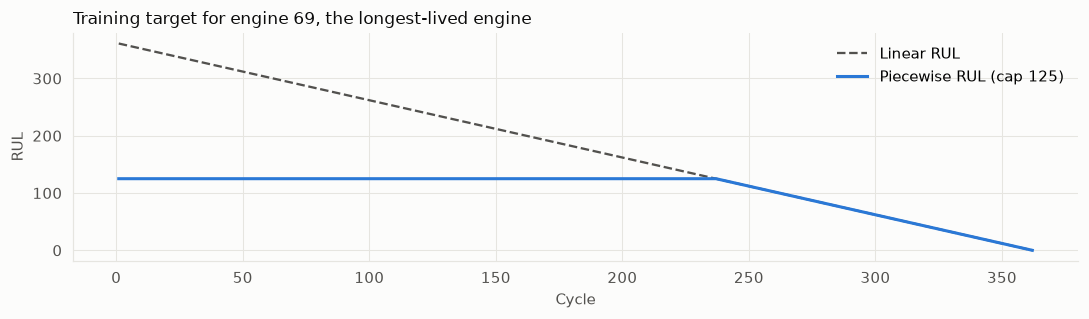

In [13]:
share_capped = (labelled["rul_linear"] > RUL_CAP).mean()
print(f"Rows with RUL above {RUL_CAP} (labelled {RUL_CAP} after capping): {share_capped:.1%}")

unit_id = train_life.idxmax()
one = labelled[labelled["unit"] == unit_id]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(one["cycle"], one["rul_linear"], color=MUTED, linewidth=1.5, linestyle="--", label="Linear RUL")
ax.plot(one["cycle"], one["rul_capped"], color=BLUE, label=f"Piecewise RUL (cap {RUL_CAP})")
ax.set(title=f"Training target for engine {unit_id}, the longest-lived engine", xlabel="Cycle", ylabel="RUL")
ax.legend()
fig.tight_layout()
plt.show()

**Findings**

- **The data supports a cap in this range, but shows a gradual bend rather than a sharp knee.** Averaged drift first exceeds its healthy baseline by three noise levels at RUL 139, inside the PDD's 110 to 140 range.
- **Most degradation signal arrives after the cap.** Only 11.3% of the total drift has happened by RUL 125, so about 89% occurs in the final 125 cycles. This backs the PDD's assumption that early degradation is relatively limited, not that it is zero.
- **The cap flattens a large share of the data:** 38.9% of training rows take the same label of 125.
- **Caveat:** RUL values above 200 only exist for the 46 engines that lived longer than 200 cycles, so the baseline and the left of this chart describe longer-lived engines only.

**Decision:** keep 125 as the default and run the planned grid search. This chart supports the range but cannot pick a single best value; validation error has to do that.

## 6. A single health index with PCA

PCA combines the 14 kept sensors into a smaller number of components. If one component captures degradation, it can act as a health index. PCA here is fitted on all training engines because this is exploration only. In the modelling pipeline, the scaler and any PCA must be fitted on the training folds alone.

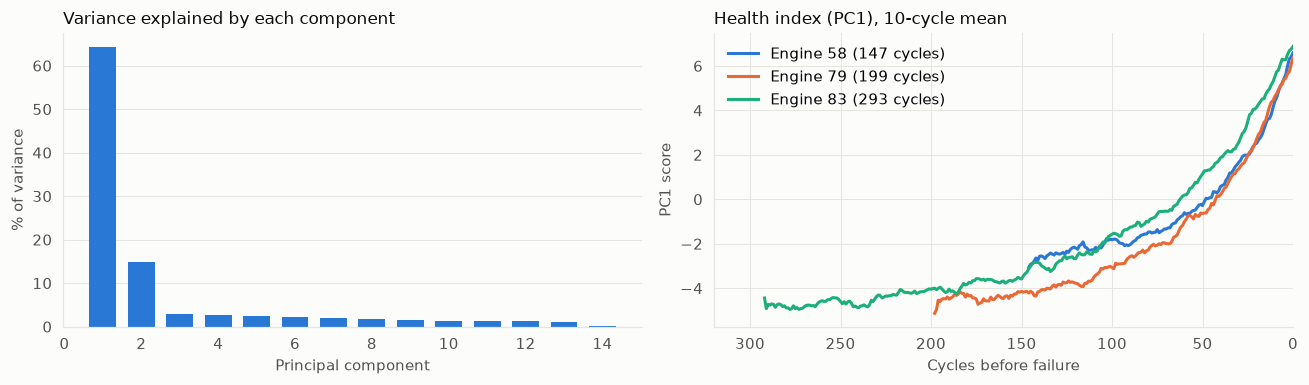

First component: 64.3% of variance; first two: 79.2%
PC1 correlation with linear RUL: -0.741
PC1 correlation with capped RUL: -0.829
PC1 across engines: first 10 cycles -2.27 (std 1.70); last 10 cycles 6.76 (std 0.31)


In [14]:
pca = PCA().fit(scaled)
explained = pd.Series(pca.explained_variance_ratio_, index=range(1, len(KEPT_SENSORS) + 1))
scores = pca.transform(scaled)
health = pd.Series(scores[:, 0], index=train.index)
if health.corr(labelled["rul_linear"]) > 0:
    health = -health  # orient so the index rises towards failure

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(explained.index, explained * 100, color=BLUE, width=0.7)
axes[0].set(title="Variance explained by each component", xlabel="Principal component", ylabel="% of variance")
axes[0].grid(axis="x", visible=False)

for unit_id, colour in zip(train_life.sort_values().index[[5, 50, 95]], [BLUE, ORANGE, "#1baf7a"]):
    mask = labelled["unit"] == unit_id
    axes[1].plot(labelled.loc[mask, "rul_linear"], health[mask].rolling(10, min_periods=1).mean(), color=colour,
                 label=f"Engine {unit_id} ({train_life[unit_id]} cycles)")
axes[1].set(title="Health index (PC1), 10-cycle mean", xlabel="Cycles before failure", ylabel="PC1 score", xlim=(320, 0))
axes[1].legend(loc="upper left")
fig.tight_layout()
plt.show()

print(f"First component: {explained.iloc[0]:.1%} of variance; first two: {explained.iloc[:2].sum():.1%}")
print(f"PC1 correlation with linear RUL: {health.corr(labelled['rul_linear']):+.3f}")
print(f"PC1 correlation with capped RUL: {health.corr(labelled['rul_capped']):+.3f}")

by_unit = health.groupby(labelled["unit"])
at_start, at_failure = by_unit.head(10).groupby(labelled["unit"]).mean(), by_unit.tail(10).groupby(labelled["unit"]).mean()
print(f"PC1 across engines: first 10 cycles {at_start.mean():.2f} (std {at_start.std():.2f}); last 10 cycles {at_failure.mean():.2f} (std {at_failure.std():.2f})")

In [15]:
components = pd.DataFrame(pca.components_[:2].T, index=KEPT_SENSORS, columns=["PC1", "PC2"])
pc2 = pd.Series(scores[:, 1], index=train.index)
print(f"PC2 correlation with capped RUL: {pc2.corr(labelled['rul_capped']):+.3f}")
components.sort_values("PC2", key=np.abs, ascending=False)

PC2 correlation with capped RUL: -0.210


,PC1,PC2
sensor_14,0.066,0.667
sensor_9,0.106,0.644
sensor_13,0.281,-0.246
sensor_8,0.282,-0.244
sensor_17,0.269,0.077
sensor_3,0.260,0.076
sensor_12,-0.304,0.063
sensor_7,-0.298,0.053
sensor_21,-0.284,-0.022
sensor_15,0.287,0.021


**Findings**

- **PC1 behaves like a health index.** It explains 64.3% of variance, draws almost evenly on 12 sensors (loadings of 0.26 to 0.31 in magnitude), and rises towards failure.
- **It matches the capped target better than the linear one:** correlation of -0.83 with capped RUL against -0.74 with linear RUL, further support for a capped target.
- **Engines start apart and finish together.** Across engines, PC1 has a standard deviation of 1.70 in the first 10 cycles and 0.31 in the last 10, ending near 6.76. A consistent failure level is useful for alerting, because the same threshold can apply across engines.
- **PC2 mostly captures sensors 9 and 14** (loadings of 0.64 and 0.67), explains 15% of variance and has a weak link with RUL (-0.21). This suggests those two sensors carry engine-specific behaviour rather than a shared degradation signal.

**Decision:** treat PC1 as a candidate extra feature and as an easy-to-read health score for the Streamlit dashboard, not as a replacement for the sensors.

## 7. Summary and decisions for the pipeline

| Finding | Evidence | Pipeline decision |
|---|---|---|
| FD001 is complete | 0 missing values, 0 skipped cycles | Keep imputation as a safeguard for live data |
| Six sensors are constant, sensor 6 is near-constant | 1 distinct value; sensor 6 has 2, with 98.0% at one value | Drop all seven, and describe sensor 6 as near-zero variance |
| `op_setting_1` to `3` carry no signal in FD001 | Correlations of about 0.01 in magnitude; `op_setting_3` constant | Exclude from FD001 inputs, and reassess for FD002 |
| 12 of 14 kept sensors trend towards failure | Median curves; correlations of 0.62 to 0.78 in magnitude | Use as inputs |
| Sensors 9 and 14 are inconsistent and highly correlated | Rise in 71 and 58 of 100 engines; correlation 0.96 | Keep at first, then test removal |
| Single-engine readings are noisy | Cycle-to-cycle change is 0.69 of the spread | Use 30-cycle rolling statistics and keep the latest reading |
| Engines differ in baseline | Over 60% of healthy-phase variance is between engines in six sensors | Split train and validation by engine (GroupKFold) |
| RUL cap is supported, with a gradual bend | Drift departs at RUL 139; 11.3% of drift reached by RUL 125 | Default 125, then grid search 110 to 140 |
| PC1 works as a health index | 64.3% of variance; -0.83 with capped RUL | Candidate feature and dashboard score, fitted on training folds only |

### Open items

1. **PDD wording:** Section 2.2 calls sensor 6 zero variance. It should say zero or near-zero variance.
2. **Test-set evaluation:** 11 of 100 test engines exceed the cap, so Week 6 needs a decision on capped or uncapped test RUL. Reporting both, and stating which is primary, avoids ambiguity when comparing with published results.
3. **FD002:** none of the sensor-dropping or trend findings above should be assumed to hold there. It is analysed separately in `02_eda_fd002.ipynb`.